# 00 · Policy Gradients, PPO and the Road to GRPO

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samaksh97/grpo-then-and-now/blob/main/notebook/00_pg_ppo_refresher.ipynb)

**GRPO, Then and Now** · optional refresher · **about 20 minutes** · CPU only, runs in about 2 seconds

Skip this notebook if you already know policy gradients and PPO, and start with `01_grpo_core.ipynb`. Here you will see when reinforcement learning with verifiable rewards (RLVR) beats supervised fine-tuning, meet the KernelBench running example, read the policy-gradient equation one symbol at a time, measure why baselines matter, and see which parts of PPO GRPO keeps and which it removes.

**You need:** probability and expectations, gradients, softmax, and short Python/NumPy programs. **Next:** `01_grpo_core.ipynb` (about 30 minutes).

In [1]:
# Setup: make grpo_lab importable
import sys, pathlib, subprocess
ROOT = next((p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "grpo_lab").exists()), None)
if ROOT is None:   # e.g. opened in Colab: fetch the repository (code, data and figures) first
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/samaksh97/grpo-then-and-now"], check=True)
    ROOT = pathlib.Path("grpo-then-and-now").resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
from grpo_lab import objectives, plots

## 1.1 Why RL after supervised fine-tuning? *(about 5 min)*

Supervised fine-tuning (SFT), the first post-training stage of InstructGPT (Ouyang et al., 2022) and most later pipelines, trains on demonstration pairs $(x, y)$ by maximizing the log-likelihood of every demonstrated token:

$$
\mathcal{L}_{\text{SFT}}(\theta) = -\sum_{t=1}^{T} \log \pi_\theta(y_t \mid y_{<t}, x)
$$

*Example (KernelBench):* $x$ = "Write an optimized CUDA kernel for $1024\times1024$ matrix multiplication"; $y$ = one human-written implementation with shared-memory tiling.

On reasoning and code tasks SFT has three limits:

1. **Imitation ceiling.** The model cannot learn a strategy that is absent from the demonstrations (for example warp-shuffle intrinsics, if every demonstration uses plain shared-memory tiling).
2. **One reference per prompt.** Many different programs are equally correct, but SFT penalizes every one that differs from the reference string.
3. **No practice on its own mistakes.** At test time the model conditions on its own tokens; SFT never shows it how to recover after an early error.

Reinforcement learning with verifiable rewards (RLVR, a term introduced with Tülu 3; Lambert et al., 2024) changes the signal from *matching tokens* to *passing a check*: the model samples its own candidates, an automated verifier scores each outcome (compiles, correct, fast), and the update makes successful candidates more likely.

| | SFT | RLVR |
|---|---|---|
| Learning signal | match this token sequence | the outcome passed the verifier |
| Granularity | every token | final outcome only |
| Main cost | expert demonstrations | a verifier plus sampling compute |
| Trains on its own samples | no | yes |

#### When to use which

| Your situation | Reach for | Why |
|---|---|---|
| Good demonstrations exist, but no program can check an answer (style, formatting, open-ended writing) | **SFT** | imitation is the only training signal available |
| The model almost never produces a correct answer yet | **SFT or distillation first** | RLVR learns only from differences between attempts; if every attempt fails there is nothing to compare (failure mode 1, `02_failure_lab.ipynb` §1) |
| A program can check answers (unit tests, a compiler, an exact final answer) and the model succeeds some of the time | **RLVR**, e.g. with GRPO | it rewards *any* correct solution rather than one reference, and it trains on the model's own mistakes |
| Quality is a matter of human preference (helpfulness, tone) | **RLHF or DPO** | no program can check it, so a learned reward model or a preference loss stands in for the verifier |

In practice the stages are combined, and the evidence suggests they do different jobs:

- **Pipelines use both.** InstructGPT ran SFT before RL from human feedback (Ouyang et al., 2022); Tülu 3 runs SFT, then DPO, then RLVR (Lambert et al., 2024). DeepSeek-R1-Zero applied GRPO directly to a base model and raised its AIME 2024 pass@1 from 15.6% to 71.0%, but its outputs were hard to read, so the released DeepSeek-R1 starts with a small "cold-start" SFT stage and then alternates RL and SFT stages (DeepSeek-AI, 2025).
- **RL tends to generalize; SFT tends to memorize.** On held-out rule and visual variants of the same task, outcome-reward RL generalized while SFT largely memorized its training data, yet SFT was still needed first to stabilize the output format (Chu et al., ICML 2025).
- **RLVR mostly sharpens what the model can already do.** RLVR-trained models beat their base models at pass@1, but the base models catch up and overtake them when allowed many attempts (large $k$ in pass@$k$): current RLVR raises the probability of reasoning paths the base model could already sample, whereas distillation from a stronger model can add new ones (Yue et al., NeurIPS 2025).

**Rule of thumb:** use SFT or distillation to teach a format or a skill the model lacks; use RLVR to make a skill the model sometimes shows reliable, whenever a program can check the answer.

> **Further reading.** Nathan Lambert's free book [*Reinforcement Learning from Human Feedback*](https://rlhfbook.com/) walks through every post-training stage (SFT, reward models, PPO, GRPO, RLVR). The Hugging Face post [*Illustrating Reinforcement Learning from Human Feedback*](https://huggingface.co/blog/rlhf) (Lambert et al., 2022) is a short visual introduction to the SFT → reward model → PPO pipeline.

## 1.2 The running example (KernelBench) and the RL loop *(about 6 min)*

#### Why GPU kernels?

Every PyTorch call (a matrix multiply, a softmax, a LayerNorm) ultimately runs as a **GPU kernel**: a small program executed in parallel by thousands of GPU threads. How well a kernel uses the GPU's memory can matter as much as the algorithm itself: FlashAttention, a carefully written attention kernel, trained GPT-2 3× faster than existing implementations (Dao et al., 2022). Writing such kernels takes rare expertise, so a natural question is whether an LLM can do it.

**KernelBench** (Ouyang et al., ICML 2025) turns that question into a benchmark: given a PyTorch reference program, write a custom kernel that computes the same result faster. Three properties make it a good running example for RLVR:

- **The reward is objective and automatic.** Compile the code, compare its outputs with PyTorch, time it. No human judge or learned reward model is involved.
- **It is hard.** Out of the box, the best frontier reasoning models matched the PyTorch baseline in fewer than 20% of cases (Ouyang et al., 2025).
- **RL works on it, and the reward gets gamed.** Kevin-32B (Baronio et al., 2025) was trained with multi-turn RL and a GRPO loss on 180 KernelBench tasks, raising its base model's correctness from 56% to 82% and its mean speedup over PyTorch from 0.53× to 1.10×. During training the model also learned to *game* the harness, for example by copying the PyTorch reference or by wrapping a broken kernel in a `try`/`except` that falls back to PyTorch, so the checks had to be hardened. `02_failure_lab.ipynb` (Appendix A) reproduces this kind of reward hacking in a toy.

The benchmark has 250 tasks in three levels: **Level 1**, 100 single operators (matrix multiplication, convolution, LayerNorm); **Level 2**, 100 simple fusions (e.g. convolution + bias + ReLU, where one fused kernel beats three separate ones); **Level 3**, 50 full architectures (e.g. MobileNet, VGG, MiniGPT). Its metric $\text{fast}_p$ is the fraction of tasks whose generated kernel is correct **and** more than $p$ times faster than PyTorch.

#### How the verifier turns a kernel into a reward

![The RL loop with a verifiable reward on KernelBench. The task prompt (state s) goes to the policy, which writes kernel code (action a). The verifier compiles it with nvcc, checks its outputs against PyTorch on random inputs, and times it. The reward is 1 only if all three checks pass, and the policy-gradient update makes passing kernels more likely.](attachment:00a_rlvr_kernelbench_loop.png)

The model answers with Python code that defines a replacement module (`ModelNew`) containing CUDA C++ source. The harness then applies three checks in order:

1. **Compiles?** PyTorch's `torch.utils.cpp_extension.load_inline` compiles the CUDA source at run time by calling **nvcc**, NVIDIA's CUDA compiler (the CUDA counterpart of `gcc`), which turns CUDA C++ into machine code the GPU can run. A syntax error, or a kernel that requests more shared memory than the GPU has, ends the attempt here.
2. **Correct?** The new module and the PyTorch reference run on the same random inputs, and their outputs must agree within a small tolerance (`torch.allclose`; KernelBench v0 and v0.1 use $\text{atol}=\text{rtol}=10^{-2}$ in fp32).
3. **Fast enough?** Both are timed on the GPU with CUDA events; the speedup is $t_{\text{PyTorch}}/t_{\text{kernel}}$.

This notebook uses a binary, $\text{fast}_p$-style reward with $p = 1.2$: $R = 1$ if the kernel compiles, is correct and is more than $1.2\times$ faster, otherwise $R = 0$. The diagram also names the RL roles: the task prompt is the **state** $s$, the LLM is the **policy** $\pi_\theta$, the generated kernel (a sequence of tokens) is the **action** $a$, and the verifier's output is the **reward** $R$. Our CPU toys keep this loop with real KernelBench task specifications but *illustrative* compile, correctness and timing outcomes (see `../data/kernelbench/README.md`). Verifiers are not infallible: GPU timing is noisy, and any gap in the checks becomes something the policy can exploit.

#### The policy-gradient equation, one symbol at a time

How should the weights $\theta$ change so that more kernels pass? The policy-gradient theorem (Williams, 1992; Sutton & Barto, 2018, ch. 13) gives the direction:

$$
\nabla_\theta J(\theta) = \mathbb{E}_{a \sim \pi_\theta(\cdot\mid s)}\Big[ \big(R(s,a) - b(s)\big)\, \nabla_\theta \log \pi_\theta(a \mid s) \Big]
$$

| Symbol | Read it as | In KernelBench |
|---|---|---|
| $J(\theta)=\mathbb{E}_{a\sim\pi_\theta}[R(s,a)]$ | the objective: the expected reward of the current policy | the model's pass rate on this task |
| $\nabla_\theta J(\theta)$ | the direction in weight space that increases $J$ fastest; training takes small steps $\theta \leftarrow \theta + \alpha\,\nabla_\theta J$ | how the weights should change so that more kernels pass |
| $\mathbb{E}_{a\sim\pi_\theta(\cdot\mid s)}[\,\cdot\,]$ | an average over answers sampled from the current model; in practice estimated from a few samples | sample several kernels for the same prompt and average |
| $\log \pi_\theta(a\mid s)=\sum_{t=1}^{T}\log\pi_\theta(a_t\mid s, a_{<t})$ | the log-probability of the whole answer, a sum over its tokens | how likely the model was to write exactly this kernel |
| $\nabla_\theta \log \pi_\theta(a\mid s)$ | the *score function*: the direction that makes this particular answer more likely | nudge the weights toward writing this kernel again |
| $R(s,a)$ | the reward | 1 if the kernel compiles, is correct and is more than $1.2\times$ faster; else 0 |
| $b(s)$ | a **baseline**: any quantity that does not depend on $a$ (Section 1.3 shows why it helps) | the current pass rate on this task, e.g. 0.4 |
| $R(s,a)-b(s)$ | the **advantage**: positive means better than expected | $+0.6$ for a passing kernel, $-0.4$ for a failing one |

**The whole equation in one sentence:** sample some answers, then raise the log-probability of each answer in proportion to how much better than expected it turned out, and lower it for the worse-than-expected ones. It is supervised learning on the model's own samples, with each sample weighted by its advantage (Karpathy, 2016). Because $\log\pi_\theta(a\mid s)$ is a sum over tokens, every token of a passing kernel receives the same push; how those per-token terms are averaged across responses of different lengths becomes failure mode 3 (`02_failure_lab.ipynb` §3).

#### Value function and advantage

The natural baseline is the expected reward for the prompt, its **value** $V(s)$:

$$
V(s) = \mathbb{E}_{a \sim \pi_\theta}[R(s, a)], \qquad A(s, a) = R(s, a) - V(s)
$$

*Example:* if the current policy succeeds on this matrix-multiplication task $40\%$ of the time, then $V(s) = 0.40$.
- A generated kernel that compiles and passes ($R = 1$) has advantage $A = 1 - 0.40 = +0.60$ $\to$ **reinforce** (push its probability up).
- A candidate that crashes or is incorrect ($R = 0$) has advantage $A = 0 - 0.40 = -0.40$ $\to$ **suppress** (push its probability down).

> **Further reading.** A one-page derivation of this equation, with code: OpenAI Spinning Up, [*Part 3: Intro to Policy Optimization*](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html). Intuition from a 130-line NumPy agent: Karpathy, [*Deep Reinforcement Learning: Pong from Pixels*](https://karpathy.github.io/2016/05/31/rl/). Textbook treatment: Sutton & Barto, [*Reinforcement Learning: An Introduction*](http://incompleteideas.net/book/the-book-2nd.html), ch. 13 (free PDF). REINFORCE in PyTorch, step by step: Hugging Face Deep RL Course, [Unit 4](https://huggingface.co/learn/deep-rl-course/unit4/introduction).
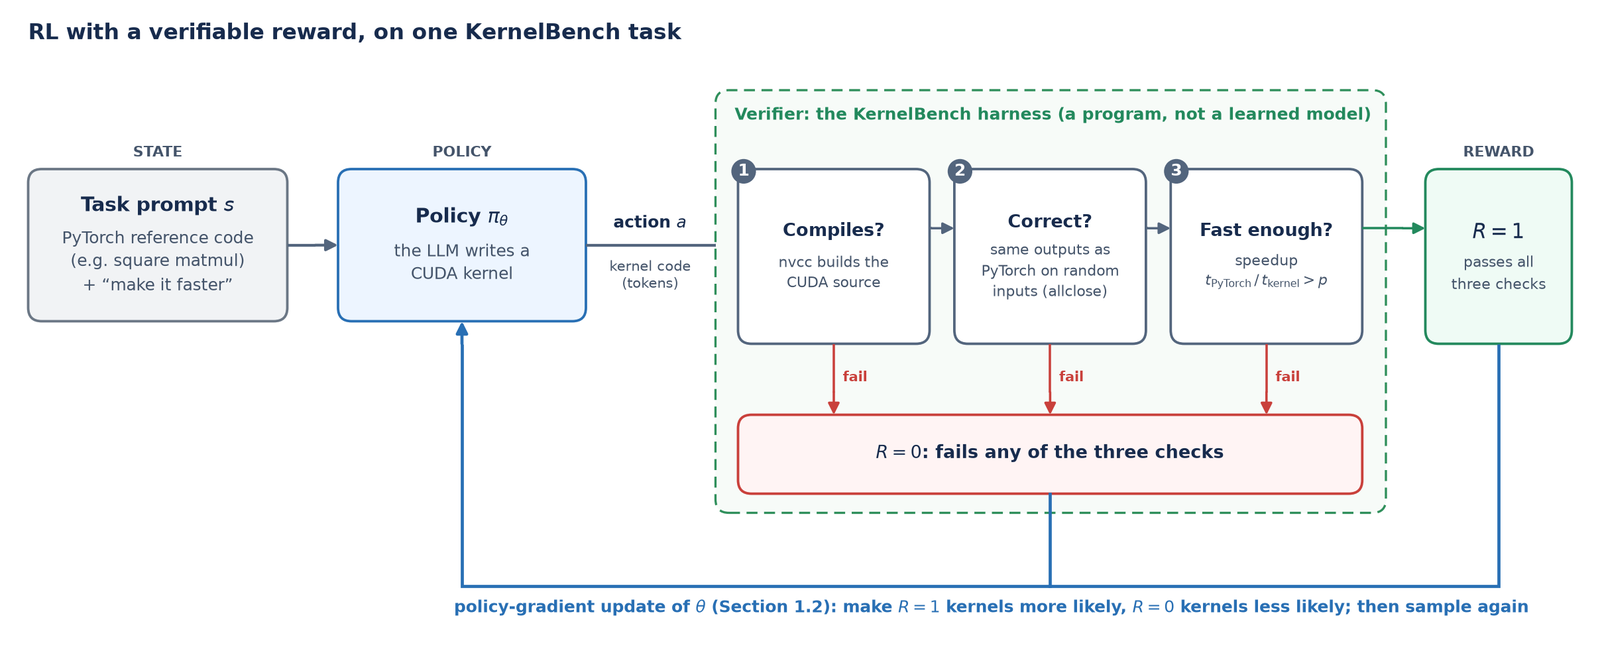

## 1.3 The variance problem and why baselines matter *(about 3 min)*

> **TL;DR:** subtracting a baseline leaves the expected policy gradient unchanged but makes its estimate much less noisy.

Before looking at PPO and GRPO, let's see *why the baseline matters so much*.

The policy gradient we defined in Section 1.2 has a critical practical problem:

$$
\nabla_\theta J = \mathbb{E}\left[ R \cdot \nabla_\theta \log \pi_\theta(a) \right]
$$

If all rewards are positive (e.g., partial credit scores between 0 and 1), then *every* action gets pushed up -- just by different amounts. The gradient is technically correct in expectation, but the **variance is enormous**. Training is noisy, slow, and unstable.

#### The baseline trick (Williams, 1992)

Subtract a **baseline** $b$ from the reward:

$$
\nabla_\theta J = \mathbb{E}\left[ (R - b) \cdot \nabla_\theta \log \pi_\theta(a) \right]
$$

This doesn't change the expected gradient (since the expectation of the score function is zero), but it **centers** the learning signal: actions with above-baseline reward get reinforced, actions with below-baseline reward get suppressed.

#### Three approaches to the baseline

| Approach | Baseline (b) | Pros | Cons |
|---|---|---|---|
| **No baseline** (REINFORCE) | b = 0 | Simple | Enormous variance |
| **PPO** | Learned critic V_psi(s) | Adaptive, low variance | Requires training a separate model |
| **GRPO** | Group mean  R_bar = (1/G) * sum(R_i) | Free, no extra model | Depends on group diversity |

PPO and GRPO are introduced in Sections 1.4–1.6. GRPO's group-mean baseline is the simplest possible choice: generate $G$ responses, compute their average reward, and subtract it. The next cell shows how much even this simple baseline helps.

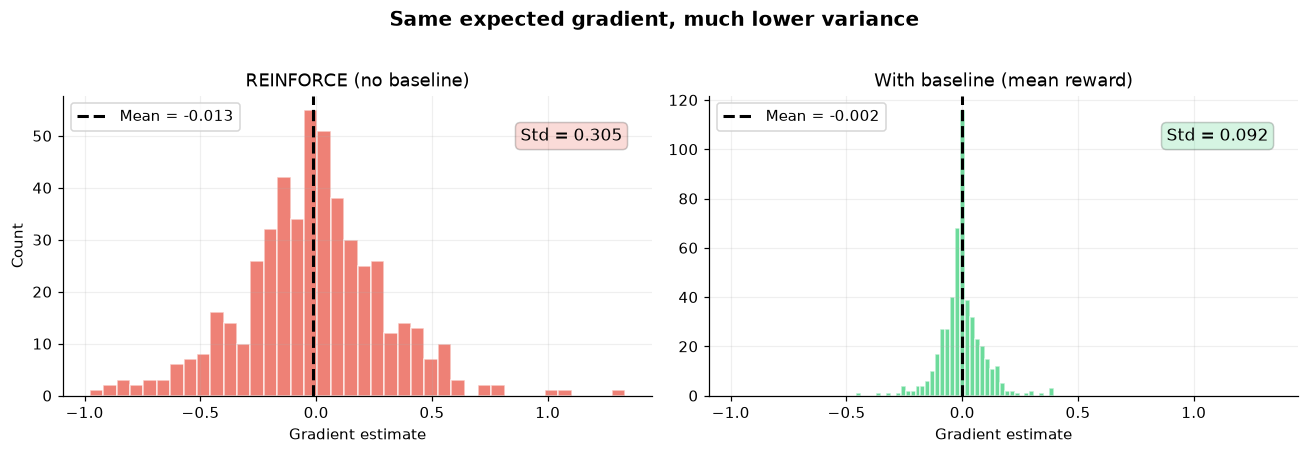

Variance 0.0928 -> 0.0085 (90.8% lower)


In [2]:
# 500 sampled answers: a reward in [0, 1] and a scalar stand-in for grad log pi (mean zero)
np.random.seed(42)
rewards = np.random.beta(3, 2, size=500)
scores = np.random.randn(500) * 0.5
reinforce_grads = rewards * scores                        # R * grad log pi
baselined_grads = (rewards - rewards.mean()) * scores     # (R - b) * grad log pi, b = mean reward
plots.variance_reduction(reinforce_grads, baselined_grads)
print(f"Variance {reinforce_grads.var():.4f} -> {baselined_grads.var():.4f} "
      f"({(1 - baselined_grads.var() / reinforce_grads.var()) * 100:.1f}% lower)")

## 1.4 PPO in three ideas: reuse samples, clip the ratio, learn a critic *(about 4 min)*

> **TL;DR:** PPO takes several gradient steps on one batch of rollouts. An importance ratio corrects for the policy having moved, clipping that ratio removes the incentive to move it beyond $1\pm\epsilon$, and a learned critic supplies the baseline.

![One PPO iteration. (1) Freeze a snapshot pi_old of the policy. (2) Sample a batch of rollouts once. (3) Score them with the learned critic to get advantages. (4) Reuse the same batch for K epochs of minibatch updates; the ratio pi_theta / pi_old starts at 1 and drifts until clipping stops that sample's gradient. Then take a new snapshot and sample again.](attachment:00b_ppo_update_loop.png)

Sampling rollouts from a language model is expensive, so we want **several gradient steps per batch** (step 4 in the figure). After the first step, the policy $\pi_\theta$ being optimized differs from the snapshot $\pi_{\text{old}}$ that generated the batch. Importance sampling corrects for this with the **probability ratio**

$$
r(\theta)=\frac{\pi_\theta(a\mid s)}{\pi_{\text{old}}(a\mid s)},\qquad
\nabla_\theta\,\mathbb{E}_{a\sim\pi_{\text{old}}}\big[r(\theta)\,A\big]=\mathbb{E}_{a\sim\pi_{\text{old}}}\big[r(\theta)\,A\,\nabla_\theta\log\pi_\theta(a\mid s)\big].
$$

At $\theta=\theta_{\text{old}}$ the ratio is 1 and this is exactly the policy gradient of Section 1.2. Maximizing $r(\theta)A$ without limits, however, rewards moving the ratio arbitrarily far on a handful of samples. **PPO-Clip** (Schulman et al., 2017) instead maximizes

$$
L^{\text{CLIP}}(\theta)=\mathbb{E}\Big[\min\big(r(\theta)A,\ \operatorname{clip}(r(\theta),1-\epsilon,1+\epsilon)\,A\big)\Big].
$$

Reading the $\min$ case by case:

| Advantage | The sample still has gradient while | Beyond that point |
|---|---|---|
| $A>0$ (better than expected) | $r<1+\epsilon$ | flat: no incentive to make the action even more likely |
| $A<0$ (worse than expected) | $r>1-\epsilon$ | flat: no incentive to make the action even less likely |

The clipped objective is a lower bound on the unclipped one, so clipping can only remove incentive, never add it. Two more pieces complete PPO as used in RLHF:

- **A learned critic** $V_\psi(s)$ predicts the expected reward and provides the advantage (step 3 in the figure), usually through generalized advantage estimation (GAE; Schulman et al., 2016). It is trained alongside the policy by regression on observed returns.
- **A KL penalty** $\beta\,\mathbb{D}_{\text{KL}}(\pi_\theta\Vert\pi_{\text{ref}})$ keeps the policy close to a frozen reference model.

**What GRPO keeps and changes:** GRPO keeps the ratio, the clipped objective and the KL penalty, and replaces the critic and GAE with statistics of a group of rollouts for the same prompt (Section 1.6). F10 draws both cases of the clipped objective; the next cell checks its gradient numerically.

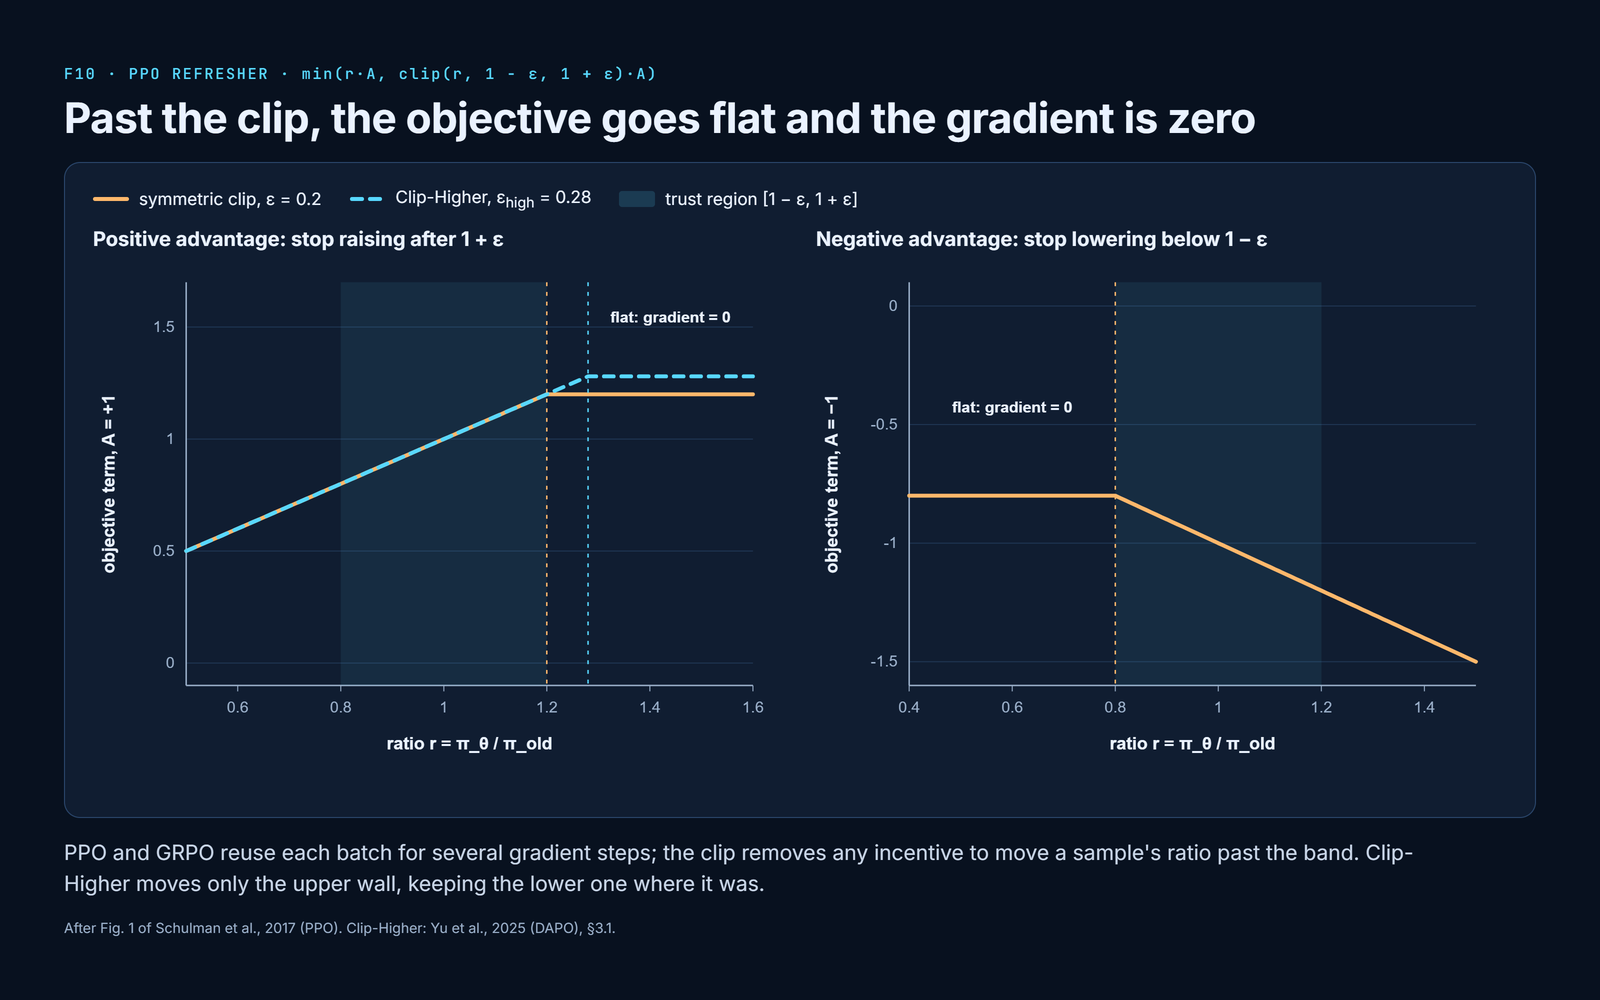

> **Further reading.** OpenAI Spinning Up's [PPO page](https://spinningup.openai.com/en/latest/algorithms/ppo.html) explains the clipped objective case by case, with pseudocode. The Hugging Face Deep RL Course, [Unit 8](https://huggingface.co/learn/deep-rl-course/unit8/introduction), builds PPO from scratch, and [*The 37 Implementation Details of Proximal Policy Optimization*](https://iclr-blog-track.github.io/2022/03/25/ppo-implementation-details/) (Huang et al., ICLR Blog Track 2022) covers what the paper leaves out.
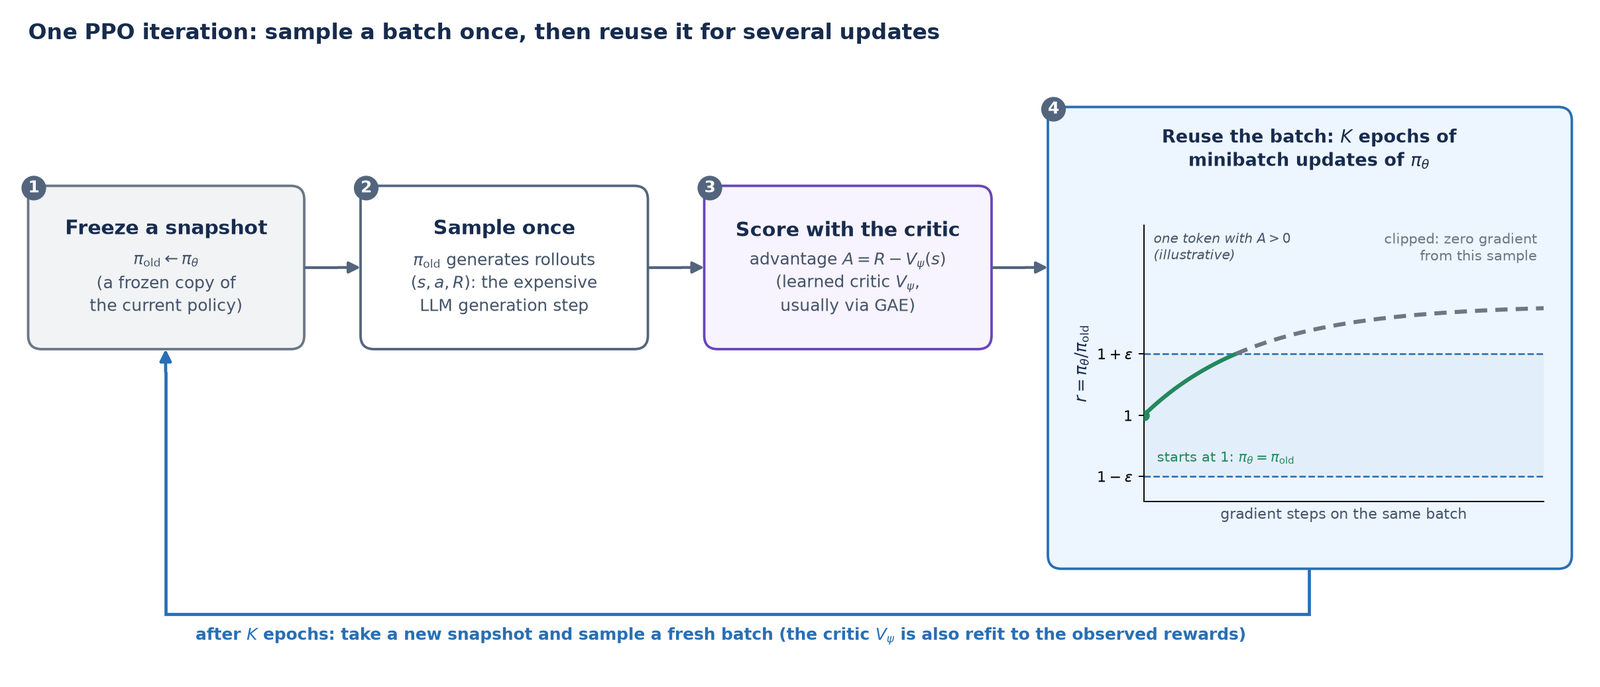

In [3]:
# d/dr of min(rA, clip(r, 0.8, 1.2) A) for a positive advantage: A inside the band, 0 once clipped
for r in (1.10, 1.30):
    print(f"r = {r:.2f}, A = +1: gradient = {float(objectives.ppo_clip_gradient(np.array(r), +1.0))}")

r = 1.10, A = +1: gradient = 1.0
r = 1.30, A = +1: gradient = 0.0


## 1.5 The full RLHF/PPO architecture (what GRPO replaces) *(about 2 min)*

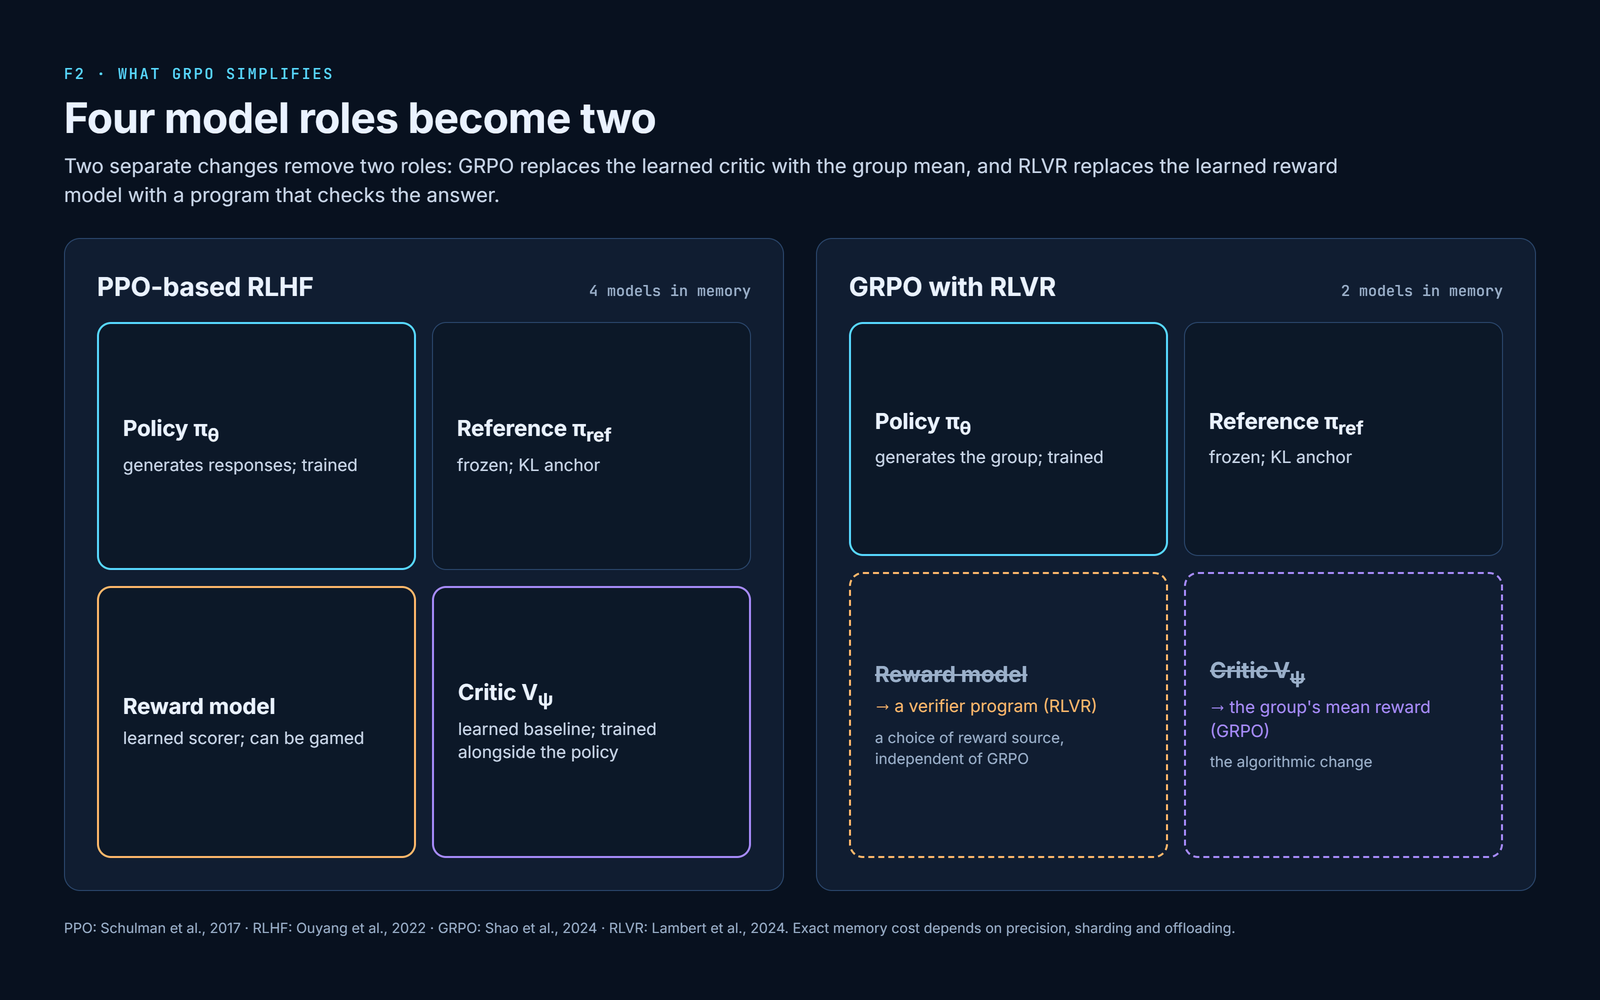

Before GRPO, the standard approach for applying RL to language models was **Proximal Policy Optimization (PPO)** within the RLHF framework (Schulman et al., 2017; Ouyang et al., 2022).

A canonical PPO-based RLHF system has **four model roles**. Implementations may shard or offload them rather than holding every full model on one GPU:

| Model | Symbol | Role in Kernel Generation | Active / Trained? | Memory Overhead |
|---|---|---|---|---|
| **1. Actor / Policy** | pi_theta | Generates candidate CUDA kernels from the prompt | **Yes (Trained)** | Model-scale weights + training state |
| **2. Reference Policy** | pi_ref | Frozen copy of initial SFT model; KL anchor preventing policy drift | **No (Frozen)** | Model-scale weights |
| **3. Reward Model** | R_phi | Neural network predicting how "good" the generated code looks | **No (Pretrained)** | Model-scale weights |
| **4. Critic / Value Model** | V_psi | Neural network predicting expected reward to provide the baseline | **Yes (Trained)** | Model-scale weights + training state |

---

#### The 5-Step PPO Training Loop

```
1. Rollout:           Prompt s --> Policy pi_theta samples candidate kernel a
2. Scoring:           Reward Model computes R_phi(s, a); Critic predicts baseline V_psi(s)
3. Advantage:         Compute advantage estimate:  A_hat = R_phi(s, a) - V_psi(s)
4. Policy Update:     Update pi_theta using clipped surrogate loss + KL penalty to pi_ref
5. Critic Update:     Update V_psi by minimizing MSE:  L_value = (V_psi(s) - R_phi)^2
```

#### Why PPO is Prohibitive for Practical Use

- **Memory Bottleneck:** Four model roles plus activations, KV caches, gradients, and optimizer states create substantial memory pressure. Exact usage depends on precision, sharding, offloading, and implementation.
- **Two Competing Training Loops:** Both the Policy (pi_theta) and Critic (V_psi) must be optimized simultaneously. An inaccurate or unstable Critic produces a noisy baseline that derails the Policy's training.
- **Reward Model Vulnerability:** In domains with reliable rule-based checks, a learned reward model may be unnecessary and can introduce exploitable approximation errors; execution and unit tests can provide the task reward directly.

> **The key distinction:** GRPO removes PPO's learned critic. Separately, RLVR tasks can use a rule-based verifier instead of a learned reward model.

## 1.6 GRPO's simplification: removing the critic, with verifiable rewards *(about 3 min)*

Group Relative Policy Optimization (GRPO), introduced in **DeepSeekMath** (Shao et al., 2024) and scaled in **DeepSeek-R1** (2025), removes the learned critic. In an RLVR setting, a second simplification comes from the task rather than from GRPO itself:

1. **RLVR simplification: Replace the Reward Model with a Deterministic Verifier.**
   In verifiable domains (math, code compilation, formal proofs), we do not need a neural network to guess if code works. We invoke `nvcc` and run test assertions directly, so no learned reward model is needed; the cost moves to compute and to designing a verifier that cannot be gamed.

2. **GRPO simplification: Replace the Critic Network with a Group-Relative Baseline.**
   Instead of training a value network to estimate expected reward, GRPO samples a **group of $G$ candidate solutions** for the same prompt and uses the group's mean reward as the empirical baseline.

![Flow diagram of one GRPO step: a prompt goes to the frozen policy, which samples a group of 8 rollouts (2 pass, 6 fail); a verifier scores them 1 or 0; the group-relative advantages are +1.73 for passes and -0.58 for fails; a clipped policy update makes passing rollouts more likely, and the updated policy samples the next batch.](attachment:F01_anatomy_of_one_grpo_step.png)

F1 traces one GRPO step on the running example: a group of eight rollouts, the verifier, the group-relative advantage and the clipped update; `01_grpo_core.ipynb` implements each box. The two simplifications are independent: GRPO also works with a learned reward model, and a verifier can also supply the reward for PPO.

---

### Architectural Comparison: PPO vs. GRPO

| Feature | PPO / Standard RLHF | GRPO (DeepSeekMath, DeepSeek-R1) |
|---|---|---|
| **Models in Memory** | 4  (pi_theta, pi_ref, R_phi, V_psi) | 2  (pi_theta, pi_ref) |
| **Models Trained** | 2  (Policy + Critic) | 1  (Policy only) |
| **Reward Signal** | Learned preference model R_phi(s, a) | Deterministic Verifier (nvcc / test harness) |
| **Baseline Source** | Learned value function V_psi(s) | Group mean:  R_bar = (1/G) * sum(R_i) |
| **Advantage Formula** | A_hat = R_phi(s, a) - V_psi(s) | A_i = (R_i - mean(R)) / (std(R) + eps) |
| **Memory Footprint** | Higher: includes critic and reward-model roles | Lower model overhead; exact savings are implementation-dependent |

The core group-relative advantage is defined as:

$$
A_i = \frac{R_i - \text{mean}(R_1, \dots, R_G)}{\text{std}(R_1, \dots, R_G) + \epsilon}
$$

---

#### The "Runners in a Heat" Intuition

Think of an athletic race. You don't need an absolute referee measuring wind speeds and altitude to decide who performed well. You simply compare each runner to **the other runners in their heat**.

- If runner *i* finishes in 10.5 seconds while everyone else in the heat took 11.2 seconds, runner *i* gets a large **positive advantage**.
- If the entire heat finishes at 10.2 seconds, that same 10.5-second time gets a **negative advantage**.

The group itself establishes the benchmark. This removes the learned critic and makes the core update comparatively straightforward to implement.
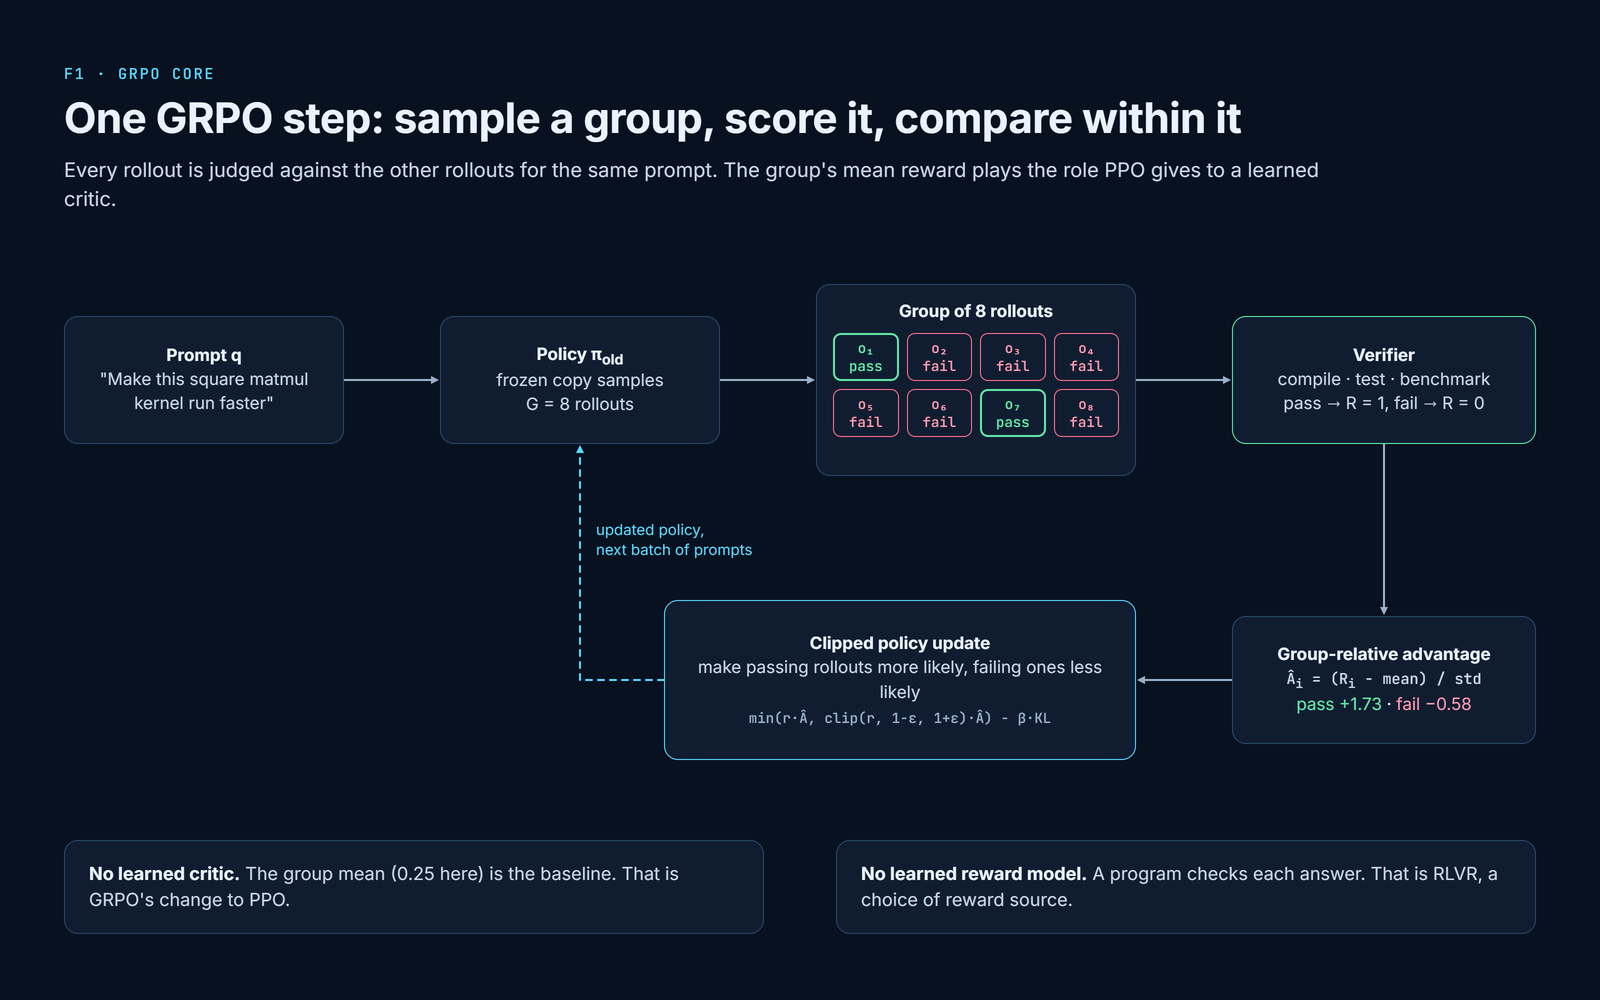

**Next:** `01_grpo_core.ipynb` computes group-relative advantages by hand, writes a 20-line Bandit-GRPO update, and runs the full clipped objective on a token-level toy.

## References

### Core Papers

1. **DeepSeekMath** (Shao et al., 2024). "DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models." *arXiv:2402.03300*. -- Introduces GRPO.

2. **DeepSeek-R1** (DeepSeek-AI, 2025). "DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning." *arXiv:2501.12948*. -- Uses GRPO in large-scale reasoning RL.

3. **DAPO** (Yu et al., 2025). "DAPO: An Open-Source LLM Reinforcement Learning System at Scale." *NeurIPS 2025*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/a4277440d50f1f15d2cb4c14f7e0c0d2-Abstract-Conference.html). -- Four techniques for stable long-CoT GRPO training.

4. **DisCO** (Li et al., 2025). "DisCO: Reinforcing Large Reasoning Models with Discriminative Constrained Optimization." *NeurIPS 2025*. *arXiv:2505.12366*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/52d6c85793b3dd47636eb430710da915-Abstract-Conference.html). -- Discriminative objective + constrained optimization.

5. **S-GRPO** (Dai et al., 2025). "S-GRPO: Early Exit via Reinforcement Learning in Reasoning Models." *NeurIPS 2025*. *arXiv:2505.07686*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/44f09d1973a88529b40029e6c3693ded-Abstract-Conference.html). -- Serial group + decaying reward for early exit.

### Case Study References

6. **KernelBench** (Ouyang et al., 2025). "KernelBench: Can LLMs Write Efficient GPU Kernels?" *ICML 2025*. [Proceedings](https://proceedings.mlr.press/v267/ouyang25a.html). -- Benchmark for GPU kernel generation.

7. **Kevin-32B** (Baronio et al., 2025). "Kevin: Multi-Turn RL for Generating CUDA Kernels." *arXiv:2507.11948*. [Paper](https://arxiv.org/abs/2507.11948). -- GRPO-based kernel optimization; documents reward hacking and multi-turn reward-attribution challenges.

### RL Foundations

8. **Sutton & Barto** (2018). "Reinforcement Learning: An Introduction." *MIT Press*, 2nd edition. [Free online edition](http://incompleteideas.net/book/the-book-2nd.html). -- Standard RL textbook; covers policy gradients, value functions, and the advantage framework used throughout this tutorial.

9. **REINFORCE** (Williams, 1992). "Simple Statistical Gradient-Following Algorithms for Connectionist Reinforcement Learning." *Machine Learning*, 8(3-4). -- The foundational policy gradient algorithm.

10. **PPO** (Schulman et al., 2017). "Proximal Policy Optimization Algorithms." *arXiv:1707.06347*. -- Clipping and trust regions.

### Additional References

11. **RLHF** (Ouyang et al., 2022). "Training Language Models to Follow Instructions with Human Feedback." *NeurIPS 2022*. -- The canonical RLHF pipeline that motivates GRPO's critic-free simplification; context for why verifiable rewards matter.

12. **DPO** (Rafailov et al., 2023). "Direct Preference Optimization: Your Language Model Is Secretly a Reward Model." *NeurIPS 2023*. -- Alternative to RL for preference alignment.

13. **DAPO NeMo RL Guide** (NVIDIA, 2025). [An In-depth Walkthrough of DAPO in NeMo RL](https://docs.nvidia.com/nemo/rl/latest/guides/dapo.html). -- Practical implementation guide.

### Additional Background (`00_pg_ppo_refresher.ipynb`)

14. **GAE** (Schulman et al., 2016). "High-Dimensional Continuous Control Using Generalized Advantage Estimation." *ICLR 2016*. *arXiv:1506.02438*. -- The advantage estimator used with PPO's learned critic.

15. **Tülu 3** (Lambert et al., 2024). "Tülu 3: Pushing Frontiers in Open Language Model Post-Training." *arXiv:2411.15124*. -- Introduces the term reinforcement learning with verifiable rewards (RLVR).

16. **SFT vs. RL** (Chu et al., 2025). "SFT Memorizes, RL Generalizes: A Comparative Study of Foundation Model Post-training." *ICML 2025*. [Proceedings](https://proceedings.mlr.press/v267/chu25c.html). -- Outcome-reward RL generalizes to unseen variants where SFT memorizes; SFT still stabilizes the output format first.

17. **Limits of RLVR** (Yue et al., 2025). "Does Reinforcement Learning Really Incentivize Reasoning Capacity in LLMs Beyond the Base Model?" *NeurIPS 2025*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/537d5aa768c2d534016a4d06f87bc8fb-Abstract-Conference.html). -- RLVR raises pass@1 but not pass@$k$ at large $k$; distillation can add new reasoning patterns.

18. **FlashAttention** (Dao et al., 2022). "FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness." *NeurIPS 2022*. *arXiv:2205.14135*. -- How much one well-written GPU kernel can matter.

### Later Revisions of the GRPO Objective (Appendix D)

19. **Dr. GRPO** (Liu et al., 2025). "Understanding R1-Zero-Like Training: A Critical Perspective." *arXiv:2503.20783*. -- Identifies GRPO's response-level length bias and question-level difficulty bias; removes both normalizations.

20. **GSPO** (Zheng et al., 2025). "Group Sequence Policy Optimization." *arXiv:2507.18071*. -- Sequence-level importance ratios and clipping.

21. **CISPO** (MiniMax, 2025). "MiniMax-M1: Scaling Test-Time Compute Efficiently with Lightning Attention." *arXiv:2506.13585*. -- Clipped IS-weight Policy Optimization.

22. **DCPO** (Yang et al., 2025). "DCPO: Dynamic Clipping Policy Optimization." *arXiv:2509.02333*. -- Clip bounds that adapt to each token's prior probability.

23. **BAPO** (Xi et al., 2026). "BAPO: Stabilizing Off-Policy Reinforcement Learning for LLMs via Balanced Policy Optimization with Adaptive Clipping." *ICLR 2026*. *arXiv:2510.18927*. -- Adaptive clip bounds that rebalance positive and negative contributions.

24. **Clip-Cov / KL-Cov** (Cui et al., 2025). "The Entropy Mechanism of Reinforcement Learning for Reasoning Language Models." *arXiv:2505.22617*. -- Entropy control by restricting updates of high-covariance tokens.

### Learning Resources (free, external)

25. **OpenAI Spinning Up** (Achiam, 2018). [Part 3: Intro to Policy Optimization](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html) and [Proximal Policy Optimization](https://spinningup.openai.com/en/latest/algorithms/ppo.html). -- Short derivations of the policy gradient and of PPO-Clip, with code.

26. **Karpathy** (2016). [Deep Reinforcement Learning: Pong from Pixels](https://karpathy.github.io/2016/05/31/rl/). -- Policy gradients as supervised learning weighted by the advantage, in 130 lines of NumPy.

27. **Hugging Face Deep RL Course.** [Unit 4: policy gradients](https://huggingface.co/learn/deep-rl-course/unit4/introduction) and [Unit 8: PPO](https://huggingface.co/learn/deep-rl-course/unit8/introduction). -- Hands-on implementations in PyTorch.

28. **Lambert** (2025). *Reinforcement Learning from Human Feedback*. [rlhfbook.com](https://rlhfbook.com/); *arXiv:2504.12501*. -- Free book on post-training: SFT, reward models, PPO, GRPO and RLVR.

29. **Lambert et al.** (2022). [Illustrating Reinforcement Learning from Human Feedback (RLHF)](https://huggingface.co/blog/rlhf). Hugging Face blog. -- A visual introduction to the SFT → reward model → PPO pipeline.

30. **Huang et al.** (2022). [The 37 Implementation Details of Proximal Policy Optimization](https://iclr-blog-track.github.io/2022/03/25/ppo-implementation-details/). *ICLR Blog Track*. -- What it takes to reproduce PPO in practice.

31. **KernelBench blog** (Ouyang, Guo and Mirhoseini). [KernelBench: Can LLMs Write GPU Kernels?](https://scalingintelligence.stanford.edu/blogs/kernelbench/) Stanford Scaling Intelligence Lab. -- Why kernels matter and how the benchmark is built.

32. **NVIDIA.** [CUDA Compiler Driver NVCC](https://docs.nvidia.com/cuda/cuda-compiler-driver-nvcc/). -- Documentation for `nvcc`, the compiler behind KernelBench's first check.